# Katta tub sonlarni generatsiya qilish algoritmlarining qiyosiy benchmarki
**AL-9624115197 “Katta tub sonlarni generatsiya qilish algoritmlarini ishlab chiqish” loyihasi uchun tajriba dasturi**

Notebook quyidagi tajribalarni bajaradi va natijalarni jadval va grafik ko‘rinishida saqlaydi:

| № | Tajriba | Savol |
|---|---|---|
| T1 | To‘g‘rilik tekshiruvi | Miller–Rabin va Baillie–PSW testlari to‘g‘ri ishlayaptimi? |
| T2 | Asosiy benchmark | Qaysi generatsiya usuli bir tub son uchun eng kam vaqt va amal sarflaydi? |
| T3 | Elak chegarasi B ni optimallashtirish | Kichik tublar bo‘yicha saralash chegarasining optimal qiymati qancha? |
| T4 | Nazariya va tajriba | Tekshirilgan nomzodlar soni Mertens formulasi bashoratiga mos keladimi? |
| T5 | Taqsimotning bir tekisligi | Inkremental qidiruv tub sonlarni notekis tanlaydimi va qanchalik? |
| T6 | Tashqi kutubxonalar | OpenSSL, sympy, gmpy2, cryptography bilan solishtirish (o‘rnatilgan bo‘lsa) |

**Muhim:** benchmarkda takrorlanuvchanlik uchun `random.Random(seed)` ishlatiladi. Haqiqiy kriptografik generatsiyada faqat `secrets` (OS entropiya manbai) ishlatilishi shart.

## 0. Sozlamalar

In [1]:
%matplotlib inline
import math, os, sys, time, random, platform, statistics, shutil, subprocess
from math import gcd, isqrt
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

# ---------------- Parametrlar ----------------
QUICK   = False            # True: tez sinov rejimi (kichik bit uzunliklari, kam takror)
SEED    = 20261101
BITS    = [256, 512] if QUICK else [256, 512, 1024, 2048]
REPEATS = 5 if QUICK else 20          # har bir (usul, bit) uchun generatsiyalar soni
MR_ROUNDS = 40                        # Miller–Rabin raundlari (konservativ qiymat)
B_DEFAULT = 2**12                     # elak / bo‘lish chegarasi (T3 da optimallashtiriladi)
B_SWEEP   = [2**k for k in range(6, 19, 2)]
BITS_B    = 512 if QUICK else 1024    # T3 uchun bit uzunligi
UNIF_BITS = 16                        # T5: kichik bit uzunligi (barcha tublarni sanash mumkin)
UNIF_N    = 30_000 if QUICK else 200_000
OUT = "benchmark_natijalar"
os.makedirs(OUT, exist_ok=True)

# gmpy2 bo‘lsa — tezroq modulli darajaga ko‘tarish
try:
    import gmpy2
    _powmod = gmpy2.powmod
    BACKEND = f"gmpy2 {gmpy2.version()}"
except ImportError:
    _powmod = pow
    BACKEND = "Python int (gmpy2 yo‘q)"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
RANGLAR = ["#1f5f8b", "#c8702a", "#4c9a6a", "#8e5ea2", "#b8433a", "#7a7f87", "#d4a72c"]
def saqla(fig, nom):
    fig.savefig(f"{OUT}/{nom}.png", bbox_inches="tight"); fig.savefig(f"{OUT}/{nom}.pdf", bbox_inches="tight")
JADVALLAR = {}

MUHIT = {"Python": sys.version.split()[0], "Platforma": platform.platform(),
         "Protsessor": platform.processor() or platform.machine(), "Arifmetika": BACKEND,
         "QUICK": QUICK, "SEED": SEED, "MR raundlari": MR_ROUNDS}
display(pd.DataFrame(MUHIT.items(), columns=["Parametr", "Qiymat"]))

,Parametr,Qiymat
0,Python,3.11.3
1,Platforma,Windows-10-10.0.26200-SP0
2,Protsessor,"Intel64 Family 6 Model 140 Stepping 1, Genuine..."
3,Arifmetika,gmpy2 2.3.2
4,QUICK,False
5,SEED,20261101
6,MR raundlari,40


## 1. Asosiy arifmetika va tublik testlari
- **Miller–Rabin (MR)** — t ta tasodifiy asos bilan kuchli psevdotublik testi; murakkab son uchun xato ehtimoli ≤ 4⁻ᵗ (eng yomon holat).
- **Baillie–PSW** — 2-asosli MR + kuchli Lyuka testi (Selfridge A usuli). Hozirgacha unga qarshi misol ma’lum emas.
- Amallar hisoblagichi: har bir modulli darajaga ko‘tarish (`powmod`) soni yoziladi — bu vaqtdan mustaqil, apparatga bog‘liq bo‘lmagan xarajat o‘lchovi.

In [2]:
STAT = Counter()
def powmod(a, e, m):
    STAT["powmod"] += 1
    return _powmod(a, e, m)

def elak(N):
    s = bytearray([1]) * (N + 1); s[0:2] = b"\x00\x00"
    for i in range(2, isqrt(N) + 1):
        if s[i]: s[i*i::i] = bytearray(len(range(i*i, N + 1, i)))
    return [i for i in range(N + 1) if s[i]]

SMALL_PRIMES = elak(2**18)
ODD_PRIMES = SMALL_PRIMES[1:]
_PRIMORIAL = {}
def primorial(B):                       # 3·5·7·…·p (p ≤ B) — gcd filtri uchun
    if B not in _PRIMORIAL:
        _PRIMORIAL[B] = math.prod(p for p in ODD_PRIMES if p <= B)
    return _PRIMORIAL[B]

def sprp(n, a):                         # kuchli psevdotublik (a asos bo‘yicha)
    d, s = n - 1, 0
    while d % 2 == 0: d //= 2; s += 1
    x = powmod(a, d, n)
    if x == 1 or x == n - 1: return True
    for _ in range(s - 1):
        x = x * x % n
        if x == n - 1: return True
    return False

def miller_rabin(n, rounds=MR_ROUNDS, rng=None):
    if n < 4: return n in (2, 3)
    if n % 2 == 0: return False
    rng = rng or random
    for _ in range(rounds):
        if not sprp(n, rng.randrange(2, n - 1)): return False
    return True

def jacobi(a, n):
    a %= n; r = 1
    while a:
        while a % 2 == 0:
            a //= 2
            if n % 8 in (3, 5): r = -r
        a, n = n, a
        if a % 4 == 3 and n % 4 == 3: r = -r
        a %= n
    return r if n == 1 else 0

def strong_lucas(n):
    if isqrt(n) ** 2 == n: return False
    D = 5
    while True:
        j = jacobi(D, n)
        if j == -1: break
        if j == 0 and abs(D) != n: return False
        D = -D - 2 if D > 0 else -D + 2
    P, Q = 1, (1 - D) // 4
    d, s = n + 1, 0
    while d % 2 == 0: d //= 2; s += 1
    STAT["powmod"] += 1                 # Lyuka zanjiri xarajati ≈ 1–2 ta powmod
    U, V, Qk = 1, P, Q % n
    for b in bin(d)[3:]:
        U, V, Qk = U * V % n, (V * V - 2 * Qk) % n, Qk * Qk % n
        if b == "1":
            U, V = P * U + V, D * U + P * V
            if U % 2: U += n
            if V % 2: V += n
            U, V, Qk = (U // 2) % n, (V // 2) % n, Qk * Q % n
    if U == 0 or V == 0: return True
    for _ in range(s - 1):
        V, Qk = (V * V - 2 * Qk) % n, Qk * Qk % n
        if V == 0: return True
    return False

def bpsw(n, rng=None):
    if n < 4: return n in (2, 3)
    for p in SMALL_PRIMES[:50]:
        if n % p == 0: return n == p
    return sprp(n, 2) and strong_lucas(n)

TESTLAR = {"MR": miller_rabin, "BPSW": bpsw}
print("Kichik tublar:", len(SMALL_PRIMES), "ta (≤ 2^18) | arifmetika:", BACKEND)

Kichik tublar: 23000 ta (≤ 2^18) | arifmetika: gmpy2 2.3.2


## 2. Generatsiya usullari
| Kod | Usul | Tavsif |
|---|---|---|
| G1 | Sodda | tasodifiy toq k-bitli son → to‘g‘ridan-to‘g‘ri tublik testi |
| G2 | Bo‘lish + test | kichik tublarga (≤ B) navbatma-navbat bo‘lib ko‘rish, so‘ng test |
| G3 | gcd-filtr + test | gcd(n, 3·5·…·p_B) = 1 sharti bitta gcd bilan, so‘ng test |
| G4 | Inkremental elak + test | tasodifiy boshlang‘ich nuqtadan oraliqni kichik tublar bilan elash (OpenSSL usuliga o‘xshash), so‘ng test |
| G5 | Isbotlanadigan (Pocklington) | rekursiv qurilish p = 2Rq + 1, q > √p; tublik Pocklington teoremasi bilan *isbotlanadi* |

G1–G4 ehtimoliy tub sonlar beradi (test turi: MR yoki BPSW). G5 Maurer / Shawe-Taylor g‘oyasiga asoslangan soddalashtirilgan variant: u FIPS 186-5 dagi algoritmning aynan nusxasi emas.

In [3]:
def tasodifiy_toq(bits, rng):
    return rng.getrandbits(bits) | (1 << (bits - 1)) | 1     # yuqori bit va toqlik majburiy

def g1_sodda(bits, rng, test):
    nomzod = 0
    while True:
        n = tasodifiy_toq(bits, rng); nomzod += 1; STAT["full_test"] += 1
        if test(n, rng=rng): return n, nomzod

def g2_bolish(bits, rng, test, B=B_DEFAULT):
    tublar = [p for p in ODD_PRIMES if p <= B]; nomzod = 0
    while True:
        n = tasodifiy_toq(bits, rng); nomzod += 1
        if any(n % p == 0 for p in tublar): continue
        STAT["full_test"] += 1
        if test(n, rng=rng): return n, nomzod

def g3_gcd(bits, rng, test, B=B_DEFAULT):
    P = primorial(B); nomzod = 0
    while True:
        n = tasodifiy_toq(bits, rng); nomzod += 1
        if gcd(n, P) != 1: continue
        STAT["full_test"] += 1
        if test(n, rng=rng): return n, nomzod

def g4_inkremental(bits, rng, test, B=B_DEFAULT):
    tublar = [p for p in ODD_PRIMES if p <= B]
    W = max(64, 2 * bits)                      # oynadagi toq o‘rinlar soni (o‘rtacha bo‘shliq ≈ 0,35·bits)
    nomzod = 0
    while True:
        n0 = tasodifiy_toq(bits, rng)
        sieve = bytearray([1]) * W                # i-o‘rin ↔ n0 + 2i
        for p in tublar:
            start = (-n0 % p) * ((p + 1) // 2) % p
            sieve[start::p] = bytearray(len(range(start, W, p)))
        for i in range(W):
            nomzod += 1
            if not sieve[i]: continue
            n = n0 + 2 * i
            if n.bit_length() != bits: break
            STAT["full_test"] += 1
            if test(n, rng=rng): return n, nomzod

def _kichik_tub(bits, rng):                    # ≤ 40 bit: deterministik MR asoslari (n < 3,3·10^24 uchun isbotlangan)
    while True:
        n = tasodifiy_toq(bits, rng)
        if all(sprp(n, a) for a in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37) if a < n) and \
           all(n % p for p in SMALL_PRIMES[:20] if p < n): return n

def g5_isbotlanadigan(bits, rng, test=None, B=B_DEFAULT, _chuqurlik=[0]):
    if bits <= 40:
        return _kichik_tub(bits, rng), 1
    q, _ = g5_isbotlanadigan((bits + 1) // 2 + 1, rng)
    lo, hi = ((1 << (bits - 1)) - 1) // (2 * q) + 1, ((1 << bits) - 2) // (2 * q)
    P = primorial(min(B, 2**12)); nomzod = 0
    while True:
        R = rng.randrange(lo, hi + 1); p = 2 * R * q + 1; nomzod += 1
        if gcd(p, P) != 1: continue
        STAT["full_test"] += 1
        # Pocklington: q tub, q | p−1, q > √p, a^(p−1) ≡ 1 va gcd(a^((p−1)/q) − 1, p) = 1  ⇒  p tub
        if q * q > p and powmod(2, p - 1, p) == 1 and gcd(powmod(2, 2 * R, p) - 1, p) == 1:
            return p, nomzod

USULLAR = {
    "G1 Sodda + MR":            (g1_sodda, "MR"),
    "G2 Bo‘lish + MR":          (g2_bolish, "MR"),
    "G3 gcd-filtr + MR":        (g3_gcd, "MR"),
    "G4 Inkremental elak + MR": (g4_inkremental, "MR"),
    "G4 Inkremental elak + BPSW": (g4_inkremental, "BPSW"),
    "G5 Isbotlanadigan (Pocklington)": (g5_isbotlanadigan, None),
}
print("Usullar:", *USULLAR, sep="\n  ")

Usullar:
  G1 Sodda + MR
  G2 Bo‘lish + MR
  G3 gcd-filtr + MR
  G4 Inkremental elak + MR
  G4 Inkremental elak + BPSW
  G5 Isbotlanadigan (Pocklington)


## T1. To‘g‘rilik tekshiruvi
Testlar 10⁶ gacha barcha sonlarda oddiy elak bilan, ma’lum psevdotub sonlarda (2-asosli kuchli psevdotublar, kuchli Lyuka psevdotublari, Karmaykl sonlari) va generatsiya qilingan katta sonlarda mustaqil tekshiriladi.

In [4]:
N = 10**6
tub_toplam = set(elak(N))
xato = Counter()
rng = random.Random(SEED)
for n in range(2, N):
    t = n in tub_toplam
    if bpsw(n) != t: xato["BPSW"] += 1
    if n < 200_000 and miller_rabin(n, 10, rng) != t: xato["MR(10)"] += 1

maxsus = {
    "2-asosli kuchli psevdotublar": [2047, 3277, 4033, 4681, 8321, 15841, 29341, 42799, 49141, 52633],
    "Kuchli Lyuka psevdotublari":   [5459, 5777, 10877, 16109, 18971, 22499, 24569, 25199, 40309, 58519],
    "Karmaykl sonlari":             [561, 1105, 1729, 2465, 2821, 6601, 8911, 10585, 15841, 29341],
}
rows = []
for nom, lst in maxsus.items():
    rows.append([nom, len(lst), sum(sprp(n, 2) for n in lst), sum(strong_lucas(n) for n in lst),
                 sum(bpsw(n) for n in lst), sum(miller_rabin(n, 20, rng) for n in lst)])
T1 = pd.DataFrame(rows, columns=["To‘plam", "Soni", "2-asosli MR o‘tkazdi", "Kuchli Lyuka o‘tkazdi",
                                 "BPSW o‘tkazdi (0 bo‘lishi kerak)", "MR(20) o‘tkazdi (0 bo‘lishi kerak)"])
# generatsiya qilingan sonlarni o‘zaro tekshirish
rng = random.Random(SEED + 1); mos = 0
for fn, tn in USULLAR.values():
    for bits in (128, 256):
        p, _ = fn(bits, rng, TESTLAR.get(tn, miller_rabin))
        mos += (bpsw(p) and miller_rabin(p, 30, rng) and p.bit_length() == bits)
print(f"n < 10^6: BPSW xatolari = {xato['BPSW']}, MR(10) xatolari (n < 2·10^5) = {xato['MR(10)']}")
print(f"Generatsiya qilingan {2*len(USULLAR)} ta son o‘zaro tekshiruvdan o‘tdi: {mos}")
JADVALLAR["T1_togrilik"] = T1; display(T1)

n < 10^6: BPSW xatolari = 0, MR(10) xatolari (n < 2·10^5) = 0
Generatsiya qilingan 12 ta son o‘zaro tekshiruvdan o‘tdi: 12


,To‘plam,Soni,2-asosli MR o‘tkazdi,Kuchli Lyuka o‘tkazdi,BPSW o‘tkazdi (0 bo‘lishi kerak),MR(20) o‘tkazdi (0 bo‘lishi kerak)
0,2-asosli kuchli psevdotublar,10,10,0,0,0
1,Kuchli Lyuka psevdotublari,10,0,10,0,0
2,Karmaykl sonlari,10,2,0,0,0


## T2. Asosiy benchmark
Har bir usul va bit uzunligi uchun `REPEATS` marta tub son generatsiya qilinadi. O‘lchanadi: vaqt (mediana va kvartillar oralig‘i), tekshirilgan nomzodlar, to‘liq tublik testlari soni, `powmod` soni.

In [5]:
def olchash(fn, bits, test_nom, repeats, seed, **kw):
    rng = random.Random(seed); test = TESTLAR.get(test_nom, miller_rabin) if test_nom else None
    natija = []
    for _ in range(repeats):
        STAT.clear(); t0 = time.perf_counter()
        p, nomzod = fn(bits, rng, test, **kw)
        dt = time.perf_counter() - t0
        assert p.bit_length() == bits
        natija.append(dict(vaqt=dt, nomzod=nomzod, toliq_test=STAT["full_test"], powmod=STAT["powmod"]))
    return natija

rows = []
for bits in BITS:
    for nom, (fn, tn) in USULLAR.items():
        r = olchash(fn, bits, tn, REPEATS, SEED + bits)
        v = [x["vaqt"] for x in r]
        rows.append(dict(bits=bits, usul=nom,
                         vaqt_med_ms=1000 * statistics.median(v),
                         vaqt_q1_ms=1000 * np.percentile(v, 25), vaqt_q3_ms=1000 * np.percentile(v, 75),
                         nomzod_ortacha=np.mean([x["nomzod"] for x in r]),
                         toliq_test_ortacha=np.mean([x["toliq_test"] for x in r]),
                         powmod_ortacha=np.mean([x["powmod"] for x in r])))
        print(f"{bits:5d} bit | {nom:34s} | {rows[-1]['vaqt_med_ms']:9.1f} ms")
T2 = pd.DataFrame(rows)
base = T2[T2.usul == "G1 Sodda + MR"].set_index("bits").vaqt_med_ms
T2["tezlanish_G1_ga_nisbatan"] = [base[b] / v for b, v in zip(T2.bits, T2.vaqt_med_ms)]
JADVALLAR["T2_asosiy_benchmark"] = T2
display(T2.round(2))

  256 bit | G1 Sodda + MR                      |       2.5 ms
  256 bit | G2 Bo‘lish + MR                    |       2.0 ms
  256 bit | G3 gcd-filtr + MR                  |       1.2 ms
  256 bit | G4 Inkremental elak + MR           |       1.5 ms
  256 bit | G4 Inkremental elak + BPSW         |       1.6 ms
  256 bit | G5 Isbotlanadigan (Pocklington)    |       1.1 ms
  512 bit | G1 Sodda + MR                      |      12.4 ms
  512 bit | G2 Bo‘lish + MR                    |       5.3 ms
  512 bit | G3 gcd-filtr + MR                  |       5.2 ms
  512 bit | G4 Inkremental elak + MR           |       5.4 ms
  512 bit | G4 Inkremental elak + BPSW         |       4.4 ms
  512 bit | G5 Isbotlanadigan (Pocklington)    |       2.5 ms
 1024 bit | G1 Sodda + MR                      |      96.7 ms
 1024 bit | G2 Bo‘lish + MR                    |      54.0 ms
 1024 bit | G3 gcd-filtr + MR                  |      53.0 ms
 1024 bit | G4 Inkremental elak + MR           |      29.2 ms
 1024 bi

,bits,usul,vaqt_med_ms,vaqt_q1_ms,vaqt_q3_ms,nomzod_ortacha,toliq_test_ortacha,powmod_ortacha,tezlanish_G1_ga_nisbatan
0,256,G1 Sodda + MR,2.45,1.48,3.44,110.65,110.65,149.65,1.00
1,256,G2 Bo‘lish + MR,1.96,1.37,3.03,94.70,14.20,53.20,1.25
2,256,G3 gcd-filtr + MR,1.24,0.88,2.16,94.70,14.20,53.20,1.97
3,256,G4 Inkremental elak + MR,1.52,1.46,1.78,104.30,15.55,54.55,1.61
4,256,G4 Inkremental elak + BPSW,1.58,1.17,1.98,94.55,12.55,13.55,1.56
5,256,G5 Isbotlanadigan (Pocklington),1.09,0.49,1.39,79.25,17.95,46.90,2.24
6,512,G1 Sodda + MR,12.37,8.48,15.93,141.90,141.90,180.90,1.00
7,512,G2 Bo‘lish + MR,5.31,4.71,8.15,146.30,20.45,59.45,2.33
8,512,G3 gcd-filtr + MR,5.24,4.25,6.92,146.30,20.45,59.45,2.36
9,512,G4 Inkremental elak + MR,5.41,4.17,7.43,236.35,32.55,71.55,2.29


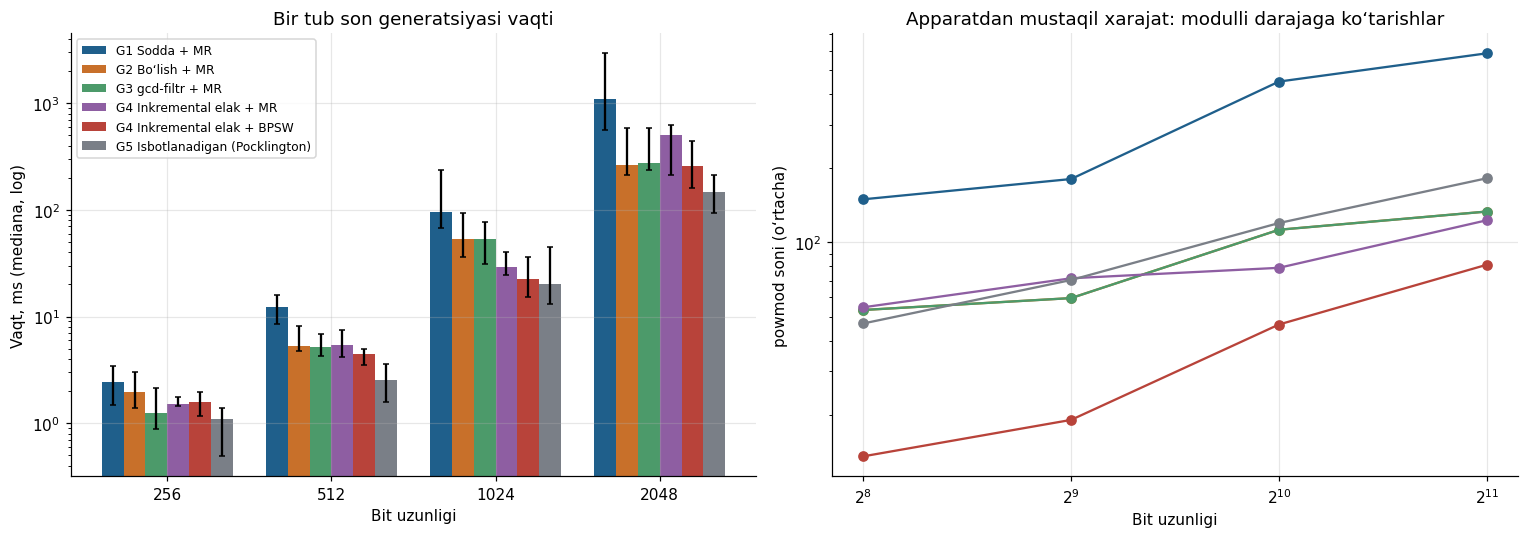

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(BITS)); w = 0.8 / len(USULLAR)
for i, nom in enumerate(USULLAR):
    d = T2[T2.usul == nom].set_index("bits").loc[BITS]
    err = [d.vaqt_med_ms - d.vaqt_q1_ms, d.vaqt_q3_ms - d.vaqt_med_ms]
    ax1.bar(x + (i - len(USULLAR)/2 + 0.5) * w, d.vaqt_med_ms, w, yerr=err, capsize=2, color=RANGLAR[i], label=nom)
    ax2.plot(BITS, d.powmod_ortacha, "o-", color=RANGLAR[i], label=nom)
ax1.set_yscale("log"); ax1.set_xticks(x, BITS); ax1.set_xlabel("Bit uzunligi"); ax1.set_ylabel("Vaqt, ms (mediana, log)")
ax1.set_title("Bir tub son generatsiyasi vaqti"); ax1.legend(fontsize=8)
ax2.set_xscale("log", base=2); ax2.set_yscale("log"); ax2.set_xlabel("Bit uzunligi"); ax2.set_ylabel("powmod soni (o‘rtacha)")
ax2.set_title("Apparatdan mustaqil xarajat: modulli darajaga ko‘tarishlar")
fig.tight_layout(); saqla(fig, "T2_asosiy_benchmark"); plt.show()

## T3. Elak chegarasi B ni optimallashtirish
Katta B ko‘proq murakkab nomzodlarni arzon usulda chiqarib tashlaydi, lekin elashning o‘zi qimmatlashadi. Optimal B ni tajribada topamiz.

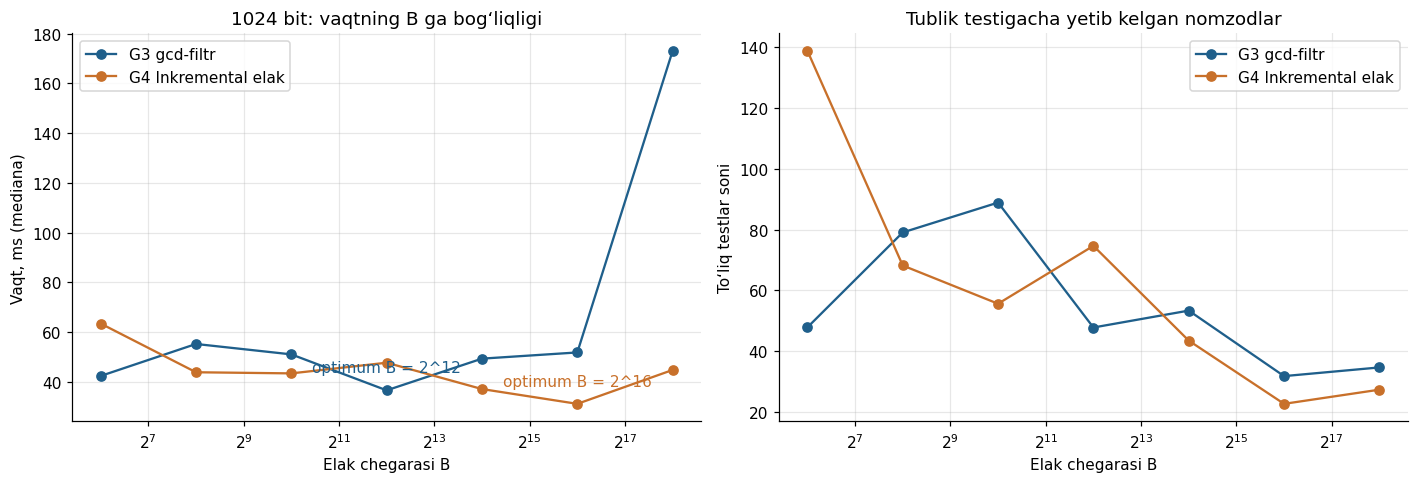

,B,usul,vaqt_med_ms,toliq_test
0,64,G3 gcd-filtr,42.35,47.90
1,64,G4 Inkremental elak,63.42,138.65
2,256,G3 gcd-filtr,55.21,79.05
3,256,G4 Inkremental elak,43.84,68.20
4,1024,G3 gcd-filtr,51.03,88.85
5,1024,G4 Inkremental elak,43.39,55.65
6,4096,G3 gcd-filtr,36.57,47.85
7,4096,G4 Inkremental elak,47.68,74.65
8,16384,G3 gcd-filtr,49.32,53.40
9,16384,G4 Inkremental elak,37.09,43.55


In [7]:
rows = []
for B in B_SWEEP:
    for nom, fn in [("G3 gcd-filtr", g3_gcd), ("G4 Inkremental elak", g4_inkremental)]:
        r = olchash(fn, BITS_B, "MR", REPEATS, SEED + B, B=B)
        rows.append(dict(B=B, usul=nom, vaqt_med_ms=1000 * statistics.median([x["vaqt"] for x in r]),
                         toliq_test=np.mean([x["toliq_test"] for x in r])))
T3 = pd.DataFrame(rows); JADVALLAR["T3_B_optimallash"] = T3
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for i, nom in enumerate(T3.usul.unique()):
    d = T3[T3.usul == nom]
    ax1.plot(d.B, d.vaqt_med_ms, "o-", color=RANGLAR[i], label=nom)
    best = d.loc[d.vaqt_med_ms.idxmin()]
    ax1.annotate(f"optimum B = 2^{int(math.log2(best.B))}", (best.B, best.vaqt_med_ms), textcoords="offset points",
                 xytext=(0, 12), ha="center", color=RANGLAR[i])
    ax2.plot(d.B, d.toliq_test, "o-", color=RANGLAR[i], label=nom)
for ax in (ax1, ax2): ax.set_xscale("log", base=2); ax.set_xlabel("Elak chegarasi B"); ax.legend()
ax1.set_ylabel("Vaqt, ms (mediana)"); ax1.set_title(f"{BITS_B} bit: vaqtning B ga bog‘liqligi")
ax2.set_ylabel("To‘liq testlar soni"); ax2.set_title("Tublik testigacha yetib kelgan nomzodlar")
fig.tight_layout(); saqla(fig, "T3_B_optimallash"); plt.show()
display(T3.round(2))

## T4. Nazariya va tajriba: tekshirilgan nomzodlar soni
k-bitli tasodifiy toq son tub bo‘lish ehtimoli ≈ 2/ln(2ᵏ). Kichik tublar (3 ≤ p ≤ B) bo‘yicha saralashdan o‘tgan nomzodlar ulushi Mertens formulasiga ko‘ra

$$\prod_{3\le p\le B}\Bigl(1-\frac1p\Bigr)\approx \frac{2e^{-\gamma}}{\ln B}.$$

Demak to‘liq testlarning kutilgan soni: E[T] ≈ (k·ln 2 / 2) · Π(1 − 1/p). Tajriba qiymati shu bashorat bilan solishtiriladi.

,bits,usul,tajriba,nazariya,nisbat
0,256,G1 Sodda + MR,110.65,88.72,1.25
1,256,G3 gcd-filtr + MR,14.20,11.95,1.19
2,512,G1 Sodda + MR,141.90,177.45,0.80
3,512,G3 gcd-filtr + MR,20.45,23.90,0.86
4,1024,G1 Sodda + MR,410.70,354.89,1.16
5,1024,G3 gcd-filtr + MR,73.60,47.81,1.54
6,2048,G1 Sodda + MR,546.60,709.78,0.77
7,2048,G3 gcd-filtr + MR,94.50,95.62,0.99
8,1024,"G3, B = 2^6",47.90,93.40,0.51
9,1024,"G3, B = 2^8",79.05,71.23,1.11


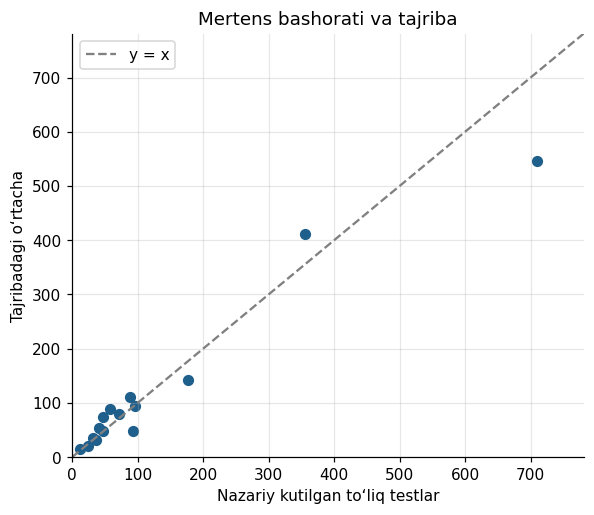

In [8]:
def kutilgan_test(bits, B):
    prod = math.prod(1 - 1 / p for p in ODD_PRIMES if p <= B) if B >= 3 else 1.0
    return bits * math.log(2) / 2 * prod

rows = []
for bits in BITS:
    for nom, B in [("G1 Sodda + MR", 2), ("G3 gcd-filtr + MR", B_DEFAULT)]:
        d = T2[(T2.usul == nom) & (T2.bits == bits)].iloc[0]
        rows.append(dict(bits=bits, usul=nom, tajriba=d.toliq_test_ortacha, nazariya=kutilgan_test(bits, B)))
for _, d in T3[T3.usul == "G3 gcd-filtr"].iterrows():
    rows.append(dict(bits=BITS_B, usul=f"G3, B = 2^{int(math.log2(d.B))}", tajriba=d.toliq_test,
                     nazariya=kutilgan_test(BITS_B, d.B)))
T4 = pd.DataFrame(rows); T4["nisbat"] = T4.tajriba / T4.nazariya
JADVALLAR["T4_nazariya_tajriba"] = T4; display(T4.round(2))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(T4.nazariya, T4.tajriba, c=RANGLAR[0], s=40)
lim = [0, max(T4.nazariya.max(), T4.tajriba.max()) * 1.1]
ax.plot(lim, lim, "--", color="gray", label="y = x"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Nazariy kutilgan to‘liq testlar"); ax.set_ylabel("Tajribadagi o‘rtacha"); ax.legend()
ax.set_title("Mertens bashorati va tajriba"); saqla(fig, "T4_nazariya_tajriba"); plt.show()

## T5. Tanlangan tub sonlar taqsimotining bir tekisligi
Inkremental qidiruvda p tub sonning tanlanish ehtimoli undan oldingi bo‘shliq uzunligiga proporsional (Brandt–Damgård). Kichik bit uzunligida barcha tub sonlarni sanab, chastotalarni ideal bir tekis taqsimot bilan solishtiramiz: χ² statistikasi, umumiy variatsiya masofasi (TV) va chastota–bo‘shliq korrelyatsiyasi.

,usul,tublar_soni,chi2,erkinlik_darajasi,chi2_ga_nisbat,TV_masofa,korr_chastota_boshliq
0,G1 Sodda (bir tekis),3030,3054.7834,3029,1.0085,0.0497,0.0181
1,G3 gcd-filtr,3030,2905.7074,3029,0.9593,0.0477,-0.0060
2,G4 Inkremental elak,3030,118433.1232,3029,39.0997,0.2891,0.9868


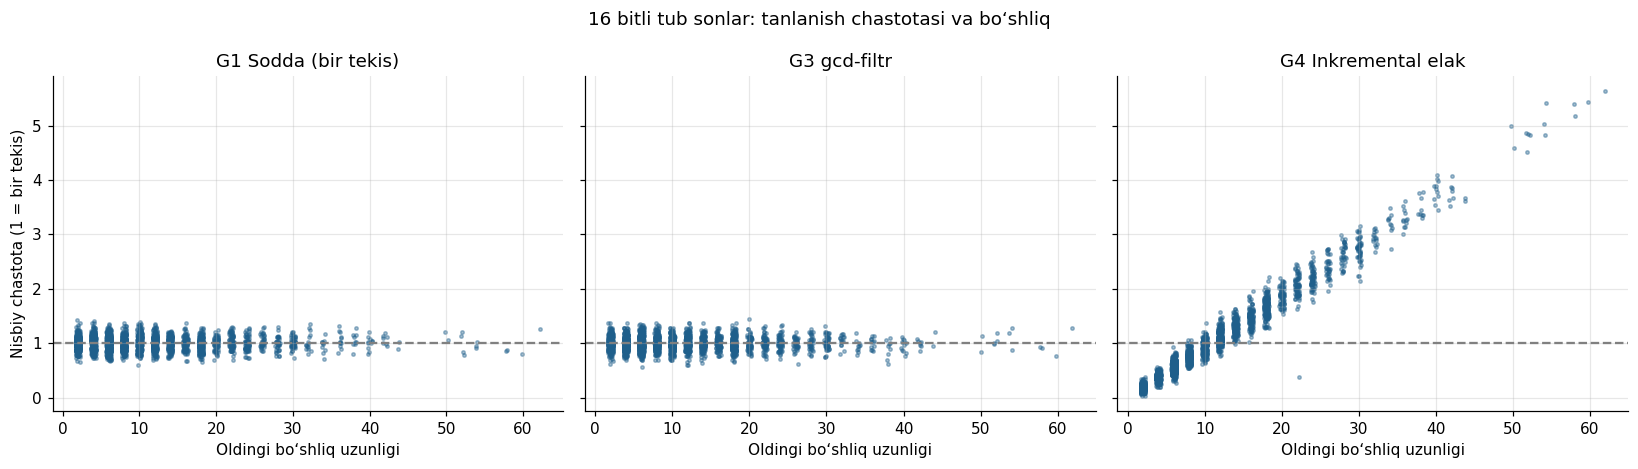

In [9]:
lo, hi = 1 << (UNIF_BITS - 1), 1 << UNIF_BITS
tublar = [p for p in elak(hi) if p >= lo]
oldingi = {p: p - q for q, p in zip([max(x for x in elak(lo)) ] + tublar[:-1], tublar)}
def chastota(fn, test_nom, N, seed):
    rng = random.Random(seed); test = TESTLAR.get(test_nom) if test_nom else None
    c = Counter(fn(UNIF_BITS, rng, test)[0] for _ in range(N))
    return np.array([c[p] for p in tublar], dtype=float)

rows, chast = [], {}
for nom, fn, tn in [("G1 Sodda (bir tekis)", g1_sodda, "MR"), ("G3 gcd-filtr", g3_gcd, "MR"),
                    ("G4 Inkremental elak", g4_inkremental, "MR")]:
    f = chastota(fn, tn, UNIF_N, SEED + 7); chast[nom] = f
    e = UNIF_N / len(tublar)
    chi2 = ((f - e) ** 2 / e).sum(); tv = 0.5 * np.abs(f / UNIF_N - 1 / len(tublar)).sum()
    r = np.corrcoef(f, [oldingi[p] for p in tublar])[0, 1]
    rows.append(dict(usul=nom, tublar_soni=len(tublar), chi2=chi2, erkinlik_darajasi=len(tublar) - 1,
                     chi2_ga_nisbat=chi2 / (len(tublar) - 1), TV_masofa=tv, korr_chastota_boshliq=r))
T5 = pd.DataFrame(rows); JADVALLAR["T5_bir_tekislik"] = T5; display(T5.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, (nom, f) in zip(axes, chast.items()):
    g = np.array([oldingi[p] for p in tublar])
    ax.scatter(g + np.random.uniform(-0.3, 0.3, len(g)), f / (UNIF_N / len(tublar)), s=5, alpha=0.4, color=RANGLAR[0])
    ax.axhline(1, color="gray", ls="--"); ax.set_title(nom); ax.set_xlabel("Oldingi bo‘shliq uzunligi")
axes[0].set_ylabel("Nisbiy chastota (1 = bir tekis)")
fig.suptitle(f"{UNIF_BITS} bitli tub sonlar: tanlanish chastotasi va bo‘shliq"); fig.tight_layout()
saqla(fig, "T5_bir_tekislik"); plt.show()

## T6. Tashqi kutubxonalar bilan solishtirish
O‘rnatilgan bo‘lsa: `openssl prime -generate` (C, buyruq qatori — jarayon ishga tushirish vaqti ham kiradi), `sympy.randprime`, `gmpy2.next_prime`, `cryptography` RSA kalit (ikki tub son). O‘rnatilmaganlari o‘tkazib yuboriladi.

,Kutubxona,bits,vaqt_med_ms
0,gmpy2.next_prime(tasodifiy),256,0.28
1,sympy.randprime,256,0.68
2,Ushbu ish: G5 Isbotlanadigan (Pocklington),256,1.09
3,OpenSSL CLI (prime -generate),256,15.61
4,gmpy2.next_prime(tasodifiy),512,1.95
5,sympy.randprime,512,2.48
6,Ushbu ish: G5 Isbotlanadigan (Pocklington),512,2.55
7,cryptography RSA kalit (2 ta tub)/2,512,4.54
8,OpenSSL CLI (prime -generate),512,16.10
9,gmpy2.next_prime(tasodifiy),1024,9.15


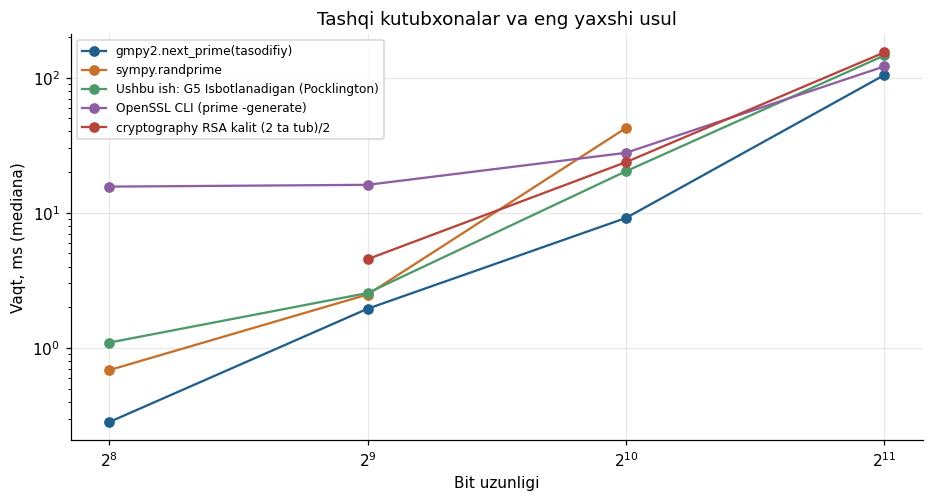

In [10]:
tashqi = []
def vaqt(f, rep):
    v = []
    for _ in range(rep):
        t0 = time.perf_counter(); f(); v.append(time.perf_counter() - t0)
    return 1000 * statistics.median(v)

rep = max(3, REPEATS // 2)
for bits in BITS:
    if shutil.which("openssl"):
        tashqi.append(("OpenSSL CLI (prime -generate)", bits,
                       vaqt(lambda: subprocess.run(["openssl", "prime", "-generate", "-bits", str(bits)],
                                                   capture_output=True, check=True), rep)))
    try:
        import sympy
        if bits <= 1024:
            tashqi.append(("sympy.randprime", bits, vaqt(lambda: sympy.randprime(2**(bits-1), 2**bits), rep)))
    except ImportError: pass
    try:
        import gmpy2
        tashqi.append(("gmpy2.next_prime(tasodifiy)", bits,
                       vaqt(lambda: gmpy2.next_prime(random.getrandbits(bits) | (1 << (bits-1))), rep)))
    except ImportError: pass
    try:
        from cryptography.hazmat.primitives.asymmetric import rsa
        if bits >= 512:
            tashqi.append(("cryptography RSA kalit (2 ta tub)/2", bits,
                           vaqt(lambda: rsa.generate_private_key(65537, 2 * bits), rep) / 2))
    except ImportError: pass
T6 = pd.DataFrame(tashqi, columns=["Kutubxona", "bits", "vaqt_med_ms"])
eng_yaxshi = T2.loc[T2.groupby("bits").vaqt_med_ms.idxmin(), ["bits", "usul", "vaqt_med_ms"]]
eng_yaxshi = eng_yaxshi.rename(columns={"usul": "Kutubxona"}); eng_yaxshi["Kutubxona"] = "Ushbu ish: " + eng_yaxshi["Kutubxona"]
T6 = pd.concat([T6, eng_yaxshi]).sort_values(["bits", "vaqt_med_ms"]).reset_index(drop=True)
JADVALLAR["T6_tashqi_kutubxonalar"] = T6; display(T6.round(2))

if len(T6):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for i, k in enumerate(T6.Kutubxona.unique()):
        d = T6[T6.Kutubxona == k]; ax.plot(d.bits, d.vaqt_med_ms, "o-", color=RANGLAR[i % len(RANGLAR)], label=k)
    ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("Bit uzunligi"); ax.set_ylabel("Vaqt, ms (mediana)")
    ax.set_title("Tashqi kutubxonalar va eng yaxshi usul"); ax.legend(fontsize=8)
    saqla(fig, "T6_tashqi"); plt.show()

## Natijalarni saqlash

In [11]:
pd.DataFrame(MUHIT.items(), columns=["Parametr", "Qiymat"]).to_csv(f"{OUT}/muhit.csv", index=False)
for nom, df in JADVALLAR.items(): df.to_csv(f"{OUT}/{nom}.csv", index=False)
try:
    with pd.ExcelWriter(f"{OUT}/benchmark_jadvallar.xlsx") as w:
        pd.DataFrame(MUHIT.items(), columns=["Parametr", "Qiymat"]).to_excel(w, sheet_name="muhit", index=False)
        for nom, df in JADVALLAR.items(): df.to_excel(w, sheet_name=nom[:31], index=False)
except Exception as e:
    print("Excel saqlanmadi:", e)
print("Saqlangan fayllar:"); [print("  ", f) for f in sorted(os.listdir(OUT))]

Saqlangan fayllar:
   T1_togrilik.csv
   T2_asosiy_benchmark.csv
   T2_asosiy_benchmark.pdf
   T2_asosiy_benchmark.png
   T3_B_optimallash.csv
   T3_B_optimallash.pdf
   T3_B_optimallash.png
   T4_nazariya_tajriba.csv
   T4_nazariya_tajriba.pdf
   T4_nazariya_tajriba.png
   T5_bir_tekislik.csv
   T5_bir_tekislik.pdf
   T5_bir_tekislik.png
   T6_tashqi.pdf
   T6_tashqi.png
   T6_tashqi_kutubxonalar.csv
   benchmark_jadvallar.xlsx
   muhit.csv


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

---
**Eslatma.** Python’dagi mutlaq vaqtlar C kutubxonalardan sekinroq bo‘ladi; usullarni solishtirishda nisbiy tezlanish va `powmod` soni (apparatdan mustaqil o‘lchov) asosiy ko‘rsatkich hisoblanadi. Maqolaga natija kiritishda `QUICK = False` bilan to‘liq ishga tushiring va kompyuter xususiyatlarini (muhit jadvali) ko‘rsating.